In [2]:
import pandas as pd
import numpy as np

In [3]:
df_drivers = pd.read_csv('master_driver.csv')
df_ride_trips = pd.read_csv('ride_trips.csv')

In [4]:
df_drivers.head()

,driver_id,nama_driver,kota_base,tahun_gabung,status
0,D001,Budi Santoso,Jakarta,2024,Aktif
1,D002,Siti Wijaya,Bandung,2020,Aktif
2,D003,Andi Hidayat,Jakarta,2023,Nonaktif
3,D004,Rina Santoso,Jakarta,2019,Aktif
4,D005,Joko Wijaya,Medan,2023,Aktif


In [5]:
df_ride_trips.head()

,trip_id,waktu_order,kota,jenis_layanan,driver_id,jarak_km,tarif,durasi_menit,rating,metode_bayar
0,T0386,2026-03-07 03:00,Surabaya,Mobil,D016,NaN,45500,56.0,5,E-Wallet
1,T0324,2026-04-10 12:13,Yogyakarta,motor,D013,8.2,24000,51.0,5,Kartu Kredit
2,T0221,24/02/2026 14:52,Yogyakarta,MOBIL,D007,2.2,13000,NaN,5,Kartu Kredit
3,T0068,2026-04-19 17:24,Bandung,Mobil,D002,2.8,14500,13.0,1,QRIS
4,T0327,09/04/2026 00:22,MEDAN,Mobil,D001,12.7,60500,67.0,4,QRIS


In [6]:
df_ride_trips.info()

<class 'pandas.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   trip_id        415 non-null    str    
 1   waktu_order    415 non-null    str    
 2   kota           415 non-null    str    
 3   jenis_layanan  415 non-null    str    
 4   driver_id      415 non-null    str    
 5   jarak_km       394 non-null    str    
 6   tarif          398 non-null    str    
 7   durasi_menit   404 non-null    float64
 8   rating         396 non-null    str    
 9   metode_bayar   408 non-null    str    
dtypes: float64(1), str(9)
memory usage: 32.6 KB


In [7]:
df_ride_trips.describe()

,durasi_menit
count,404.000000
mean,36.413366
std,18.207514
min,3.000000
25%,22.000000
50%,36.000000
75%,48.000000
max,99.000000


In [8]:
df_ride_trips.isna().sum()

trip_id           0
waktu_order       0
kota              0
jenis_layanan     0
driver_id         0
jarak_km         21
tarif            17
durasi_menit     11
rating           19
metode_bayar      7
dtype: int64

In [9]:
df_ride_trips['waktu_order'] = pd.to_datetime(df_ride_trips['waktu_order'], format='mixed', errors='coerce')
df_ride_trips['kota'] = df_ride_trips['kota'].str.title().str.strip()
df_ride_trips['jenis_layanan'] = df_ride_trips['jenis_layanan'].str.title().str.strip()
df_ride_trips['jarak_km'] = pd.to_numeric(df_ride_trips['jarak_km'], errors='coerce')
df_ride_trips['jarak_km'] = df_ride_trips['jarak_km'].fillna(df_ride_trips.groupby('jenis_layanan')['jarak_km'].transform('median'))
df_ride_trips['tarif'] = (
    df_ride_trips['tarif']
    .astype(str)
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.strip()
)
df_ride_trips['tarif'] = pd.to_numeric(df_ride_trips['tarif'], errors='coerce')
df_ride_trips['tarif'] = df_ride_trips['tarif'].replace('-', np.nan)
df_ride_trips['rating'] = pd.to_numeric(df_ride_trips['rating'], errors='coerce')
df_ride_trips['metode_bayar'] = df_ride_trips['metode_bayar'].fillna('unknown')
df_ride_trips['metode_bayar'].value_counts(dropna=False)

metode_bayar
QRIS            108
E-Wallet        103
Kartu Kredit     96
Cash             91
unknown          17
Name: count, dtype: int64

In [10]:
q1 = df_ride_trips.groupby('jenis_layanan')['tarif'].transform(lambda s: s.quantile(0.25))
q3 = df_ride_trips.groupby('jenis_layanan')['tarif'].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

mask = (df_ride_trips['tarif'] < q1 - 1.5*iqr) | (df_ride_trips['tarif'] > q3 + 1.5*iqr)
df_ride_trips[mask]

,trip_id,waktu_order,kota,jenis_layanan,driver_id,jarak_km,tarif,durasi_menit,rating,metode_bayar
65,T0215,2026-03-22 14:29:00,Yogyakarta,Mobil,D019,0.7,160000.0,11.0,1.0,E-Wallet
136,T0193,2026-11-03 10:14:00,Yogyakarta,Motor,D017,3.2,180000.0,19.0,3.0,Kartu Kredit
173,T0247,2026-01-26 17:33:00,Surabaya,Kirim Barang,D009,6.8,520000.0,48.0,5.0,Cash
177,T0373,2026-02-16 22:55:00,Yogyakarta,Mobil,D017,15.0,1380000.0,59.0,1.0,QRIS
178,T0114,2026-03-10 08:15:00,Bandung,Mobil,D020,2.3,250000.0,19.0,5.0,QRIS
194,T0381,2026-03-24 15:14:00,Medan,Motor,D014,12.3,690000.0,67.0,2.0,Cash
243,T0347,2026-04-19 04:07:00,Jakarta,Kirim Barang,D019,17.6,58500.0,94.0,3.0,Cash
268,T0089,2026-05-26 01:04:00,Medan,Kirim Barang,D019,10.9,760000.0,53.0,5.0,QRIS
394,T0081,2026-05-30 21:13:00,Medan,Kirim Barang,D005,16.6,55500.0,62.0,3.0,QRIS


In [11]:
df_ride_trips.loc[mask, 'tarif'] = np.nan

In [12]:
q1 = df_ride_trips.groupby('jenis_layanan')['tarif'].transform(lambda s: s.quantile(0.25))
q3 = df_ride_trips.groupby('jenis_layanan')['tarif'].transform(lambda s: s.quantile(0.75))
iqr = q3 - q1

mask = (df_ride_trips['tarif'] < q1 - 1.5*iqr) | (df_ride_trips['tarif'] > q3 + 1.5*iqr)
df_ride_trips[mask]

,trip_id,waktu_order,kota,jenis_layanan,driver_id,jarak_km,tarif,durasi_menit,rating,metode_bayar


In [13]:
df_ride_trips.isna().sum()

trip_id           0
waktu_order       0
kota              0
jenis_layanan     0
driver_id         0
jarak_km          0
tarif            29
durasi_menit     11
rating           40
metode_bayar      0
dtype: int64

In [14]:
df_ride_trips.head()

,trip_id,waktu_order,kota,jenis_layanan,driver_id,jarak_km,tarif,durasi_menit,rating,metode_bayar
0,T0386,2026-03-07 03:00:00,Surabaya,Mobil,D016,6.85,45500.0,56.0,5.0,E-Wallet
1,T0324,2026-04-10 12:13:00,Yogyakarta,Motor,D013,8.20,24000.0,51.0,5.0,Kartu Kredit
2,T0221,2026-02-24 14:52:00,Yogyakarta,Mobil,D007,2.20,13000.0,NaN,5.0,Kartu Kredit
3,T0068,2026-04-19 17:24:00,Bandung,Mobil,D002,2.80,14500.0,13.0,1.0,QRIS
4,T0327,2026-09-04 00:22:00,Medan,Mobil,D001,12.70,60500.0,67.0,4.0,QRIS


In [15]:
'''Kolom Baru'''

df_ride_trips['jam'] = df_ride_trips['waktu_order'].dt.hour
df_ride_trips['hari'] = df_ride_trips['waktu_order'].dt.day_name(locale='id_ID')
df_ride_trips['bulan'] = df_ride_trips['waktu_order'].dt.month_name(locale='id_ID')
df_ride_trips['tarif_per_km'] = df_ride_trips['tarif'] / df_ride_trips['jarak_km'].round(0)
df_ride_trips['kategori_jarak'] = pd.cut(
    df_ride_trips['jarak_km'],
    bins=[0, 3, 10, np.inf],
    labels=['Dekat', 'Sedang', 'Jauh']
)
df_ride_trips['waktu_hari'] = pd.cut(
    df_ride_trips['jam'],
    bins=[0, 5, 11, 15, 19, 24],
    labels=['Malam', 'Pagi', 'Siang', 'Sore', 'Malam'],
    right=False,
    ordered=False
)
df_ride_trips['bulan_num'] = df_ride_trips['waktu_order'].dt.month

df_ride_trips['durasi_menit'] = df_ride_trips['durasi_menit'].fillna(df_ride_trips.groupby(['jenis_layanan', 'kategori_jarak'], observed=True)['durasi_menit'].transform('median'))
df_ride_trips['tarif'] = df_ride_trips['tarif'].fillna(df_ride_trips.groupby(['jenis_layanan', 'kategori_jarak'], observed=True)['tarif'].transform('median'))

df_ride_trips

,trip_id,waktu_order,kota,jenis_layanan,driver_id,jarak_km,tarif,durasi_menit,rating,metode_bayar,jam,hari,bulan,tarif_per_km,kategori_jarak,waktu_hari,bulan_num
0,T0386,2026-03-07 03:00:00,Surabaya,Mobil,D016,6.85,45500.0,56.0,5.0,E-Wallet,3,Sabtu,Maret,6500.000000,Sedang,Malam,3
1,T0324,2026-04-10 12:13:00,Yogyakarta,Motor,D013,8.20,24000.0,51.0,5.0,Kartu Kredit,12,Jumat,April,3000.000000,Sedang,Siang,4
2,T0221,2026-02-24 14:52:00,Yogyakarta,Mobil,D007,2.20,13000.0,12.0,5.0,Kartu Kredit,14,Selasa,Februari,6500.000000,Dekat,Siang,2
3,T0068,2026-04-19 17:24:00,Bandung,Mobil,D002,2.80,14500.0,13.0,1.0,QRIS,17,Minggu,April,4833.333333,Dekat,Sore,4
4,T0327,2026-09-04 00:22:00,Medan,Mobil,D001,12.70,60500.0,67.0,4.0,QRIS,0,Jumat,September,4653.846154,Jauh,Malam,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,T0128,2026-05-15 06:40:00,Bandung,Kirim Barang,D020,12.00,42000.0,56.0,5.0,Kartu Kredit,6,Jumat,Mei,3500.000000,Jauh,Pagi,5
411,T0213,2026-04-22 23:48:00,Surabaya,Motor,D009,5.30,15500.0,19.0,NaN,E-Wallet,23,Rabu,April,3100.000000,Sedang,Malam,4
412,T0090,2026-01-28 13:36:00,Medan,Mobil,D002,2.90,17500.0,20.0,1.0,QRIS,13,Rabu,Januari,5833.333333,Dekat,Siang,1
413,T0314,2026-06-20 10:49:00,Medan,Motor,D020,0.50,3000.0,5.0,5.0,Kartu Kredit,10,Sabtu,Juni,inf,Dekat,Pagi,6


In [16]:
df_ride_trips['tarif_per_km'] = df_ride_trips['tarif'] / df_ride_trips['jarak_km']

In [17]:
df_ride_trips.isna().sum()

trip_id            0
waktu_order        0
kota               0
jenis_layanan      0
driver_id          0
jarak_km           0
tarif              0
durasi_menit       0
rating            40
metode_bayar       0
jam                0
hari               0
bulan              0
tarif_per_km       0
kategori_jarak     0
waktu_hari         0
bulan_num          0
dtype: int64

In [18]:
total_pendapatan = df_ride_trips.groupby('kota')['tarif'].sum().sort_values(ascending=False).reset_index()

ringkasan_per_jenis_layanan = df_ride_trips.groupby('jenis_layanan').agg(
    rata_rata_tarif=('tarif', 'mean'),
    median_jarak=('jarak_km', 'median'),
    rata_rata_rating=('rating', 'mean')
).round(2).reset_index()

pivot_kota = pd.pivot_table(
    df_ride_trips,
    index='kota',
    columns='jenis_layanan',
    values='trip_id',
    aggfunc='count',
    fill_value=0,
    margins=True,
    margins_name='Total'
)

print(total_pendapatan)
print('\n')
print(ringkasan_per_jenis_layanan)
print('\n')
print(pivot_kota)

         kota      tarif
0       Medan  2624750.0
1     Jakarta  2194500.0
2     Bandung  2116750.0
3    Surabaya  2044000.0
4  Yogyakarta  1804500.0


  jenis_layanan  rata_rata_tarif  median_jarak  rata_rata_rating
0  Kirim Barang         24010.64          6.15              3.72
1         Mobil         34619.57          6.85              3.71
2         Motor         19275.74          7.10              3.39


jenis_layanan  Kirim Barang  Mobil  Motor  Total
kota                                            
Bandung                  22     33     20     75
Jakarta                  24     28     32     84
Medan                    49     26     29    104
Surabaya                 18     29     27     74
Yogyakarta               28     22     28     78
Total                   141    138    136    415


In [19]:
rata_rata_tarif = df_ride_trips.groupby(['jenis_layanan', 'kategori_jarak'])['tarif_per_km'].mean().unstack().reset_index()

jam_ramai = (
    df_ride_trips
    .groupby('jam')['trip_id']
    .count()
    .sort_values(ascending=False)
    .reset_index(name='jumlah_trip').head(5)
)

hari_sepi = (
    df_ride_trips
    .groupby('hari')['trip_id']
    .count()
    .sort_values(ascending=True)
    .reset_index(name='jumlah_trip')
)

print(rata_rata_tarif)
print('\n')
print(jam_ramai)
print('\n')
print(hari_sepi)

kategori_jarak jenis_layanan        Dekat       Sedang         Jauh
0               Kirim Barang  6765.114283  3859.953526  3369.616334
1                      Mobil  8360.661032  5314.090817  4791.133101
2                      Motor  3372.858063  2786.400563  2609.550360


   jam  jumlah_trip
0   15           26
1   21           25
2   23           24
3    2           22
4   13           21


     hari  jumlah_trip
0   Jumat           47
1   Kamis           51
2  Selasa           58
3    Rabu           59
4   Senin           62
5  Minggu           69
6   Sabtu           69


In [20]:
hitung = (
    df_ride_trips
    .groupby(['kota', 'metode_bayar'])['trip_id']
    .count()
    .reset_index(name='jumlah')
)

paling_sering = hitung.loc[hitung.groupby('kota')['jumlah'].idxmax()]
print(paling_sering)

          kota  metode_bayar  jumlah
3      Bandung          QRIS      21
6      Jakarta      E-Wallet      23
11       Medan      E-Wallet      30
17    Surabaya  Kartu Kredit      21
22  Yogyakarta  Kartu Kredit      21


In [21]:
'''Join Merge'''

dfleft = df_ride_trips.merge(df_drivers, on='driver_id', how='left', indicator=True)

driver_missing = dfleft[dfleft['_merge'] == 'left_only']
driver_missing

,trip_id,waktu_order,kota,jenis_layanan,driver_id,jarak_km,tarif,durasi_menit,rating,metode_bayar,...,bulan,tarif_per_km,kategori_jarak,waktu_hari,bulan_num,nama_driver,kota_base,tahun_gabung,status,_merge
37,T0301,2026-01-13 20:53:00,Surabaya,Mobil,D022,9.80,45500.0,44.0,4.0,Cash,...,Januari,4642.857143,Sedang,Malam,1,NaN,NaN,NaN,NaN,left_only
56,T0135,2026-01-26 10:55:00,Bandung,Motor,D022,6.70,19250.0,38.0,5.0,QRIS,...,Januari,2873.134328,Sedang,Pagi,1,NaN,NaN,NaN,NaN,left_only
67,T0187,2026-02-27 03:29:00,Bandung,Kirim Barang,D022,6.60,23500.0,29.0,3.0,Kartu Kredit,...,Februari,3560.606061,Sedang,Malam,2,NaN,NaN,NaN,NaN,left_only
81,T0252,2026-03-07 09:38:00,Yogyakarta,Motor,D021,7.10,4000.0,6.0,1.0,E-Wallet,...,Maret,563.380282,Sedang,Pagi,3,NaN,NaN,NaN,NaN,left_only
82,T0360,2026-05-19 17:04:00,Bandung,Kirim Barang,D021,7.80,24500.0,43.0,5.0,QRIS,...,Mei,3141.025641,Sedang,Sore,5,NaN,NaN,NaN,NaN,left_only
90,T0257,2026-06-08 03:55:00,Bandung,Motor,D021,9.70,26000.0,47.0,NaN,Cash,...,Juni,2680.412371,Sedang,Malam,6,NaN,NaN,NaN,NaN,left_only
98,T0153,2026-03-30 16:36:00,Bandung,Kirim Barang,D022,4.40,18500.0,29.0,4.0,Kartu Kredit,...,Maret,4204.545455,Sedang,Sore,3,NaN,NaN,NaN,NaN,left_only
117,T0275,2026-05-08 20:03:00,Bandung,Kirim Barang,D022,4.20,17000.0,25.0,4.0,unknown,...,Mei,4047.619048,Sedang,Malam,5,NaN,NaN,NaN,NaN,left_only
124,T0169,2026-03-12 16:23:00,Yogyakarta,Kirim Barang,D022,13.10,44500.0,78.0,4.0,Kartu Kredit,...,Maret,3396.946565,Jauh,Sore,3,NaN,NaN,NaN,NaN,left_only
131,T0051,2026-06-14 03:34:00,Medan,Kirim Barang,D022,4.50,17500.0,35.0,5.0,E-Wallet,...,Juni,3888.888889,Sedang,Malam,6,NaN,NaN,NaN,NaN,left_only


In [22]:
dfleft = dfleft.drop(columns='_merge')

In [23]:
dfleft

,trip_id,waktu_order,kota,jenis_layanan,driver_id,jarak_km,tarif,durasi_menit,rating,metode_bayar,...,hari,bulan,tarif_per_km,kategori_jarak,waktu_hari,bulan_num,nama_driver,kota_base,tahun_gabung,status
0,T0386,2026-03-07 03:00:00,Surabaya,Mobil,D016,6.85,45500.0,56.0,5.0,E-Wallet,...,Sabtu,Maret,6642.335766,Sedang,Malam,3,Wulan Pratama,Jakarta,2020.0,Aktif
1,T0324,2026-04-10 12:13:00,Yogyakarta,Motor,D013,8.20,24000.0,51.0,5.0,Kartu Kredit,...,Jumat,April,2926.829268,Sedang,Siang,4,Hadi Lestari,Jakarta,2023.0,Aktif
2,T0221,2026-02-24 14:52:00,Yogyakarta,Mobil,D007,2.20,13000.0,12.0,5.0,Kartu Kredit,...,Selasa,Februari,5909.090909,Dekat,Siang,2,Agus Wijaya,Yogyakarta,2023.0,Aktif
3,T0068,2026-04-19 17:24:00,Bandung,Mobil,D002,2.80,14500.0,13.0,1.0,QRIS,...,Minggu,April,5178.571429,Dekat,Sore,4,Siti Wijaya,Bandung,2020.0,Aktif
4,T0327,2026-09-04 00:22:00,Medan,Mobil,D001,12.70,60500.0,67.0,4.0,QRIS,...,Jumat,September,4763.779528,Jauh,Malam,9,Budi Santoso,Jakarta,2024.0,Aktif
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
410,T0128,2026-05-15 06:40:00,Bandung,Kirim Barang,D020,12.00,42000.0,56.0,5.0,Kartu Kredit,...,Jumat,Mei,3500.000000,Jauh,Pagi,5,Putri Hidayat,Bandung,2020.0,Nonaktif
411,T0213,2026-04-22 23:48:00,Surabaya,Motor,D009,5.30,15500.0,19.0,NaN,E-Wallet,...,Rabu,April,2924.528302,Sedang,Malam,4,Eko Pratama,Surabaya,2020.0,Aktif
412,T0090,2026-01-28 13:36:00,Medan,Mobil,D002,2.90,17500.0,20.0,1.0,QRIS,...,Rabu,Januari,6034.482759,Dekat,Siang,1,Siti Wijaya,Bandung,2020.0,Aktif
413,T0314,2026-06-20 10:49:00,Medan,Motor,D020,0.50,3000.0,5.0,5.0,Kartu Kredit,...,Sabtu,Juni,6000.000000,Dekat,Pagi,6,Putri Hidayat,Bandung,2020.0,Nonaktif


In [24]:
top_5_driver_pendapatan = (
    dfleft
    .groupby(['driver_id', 'nama_driver', 'kota_base'])
    .agg(
        total_pendapatan=('tarif', 'sum'),
        rata_rata_rating=('rating', 'mean')
    )
    .round(2)
    .sort_values('total_pendapatan', ascending=False)
    .head(5)
    .reset_index()
)

top_5_driver_pendapatan

,driver_id,nama_driver,kota_base,total_pendapatan,rata_rata_rating
0,D013,Hadi Lestari,Jakarta,873500.0,3.81
1,D019,Dimas Pratama,Jakarta,641750.0,3.67
2,D015,Fajar Santoso,Jakarta,639500.0,3.43
3,D009,Eko Pratama,Surabaya,595500.0,4.00
4,D007,Agus Wijaya,Yogyakarta,583500.0,3.17


In [25]:
'''Presentase Trip'''

valid = dfleft[dfleft['kota_base'].notna()]   # buang trip tanpa data driver (D021, D022)

luar_kota = valid['kota'] != valid['kota_base']
persen = luar_kota.mean() * 100
print(f"{persen:.2f}%")

81.58%


In [26]:
'''Presentase Trip'''

nonaktif = dfleft[dfleft['status'] == 'Nonaktif']

len(nonaktif)                          # jumlah trip dari driver nonaktif
nonaktif['driver_id'].nunique()        # berapa driver nonaktif yang punya trip
nonaktif.groupby('nama_driver').size() # rinciannya per driver

nama_driver
Andi Hidayat     16
Dewi Hidayat     18
Lina Pratama     19
Maya Santoso     16
Putri Hidayat    15
dtype: int64

In [27]:
'''Bandingkan rata-rata rating driver berdasarkan tahun_gabung'''

rating_per_tahun = (
    dfleft
    .groupby('tahun_gabung')
    .agg(
        rata_rata_rating=('rating', 'mean'),
        jumlah_rating=('rating', 'count'),
        jumlah_driver=('driver_id', 'nunique')
    )
    .round(2)
)

print(rating_per_tahun)

              rata_rata_rating  jumlah_rating  jumlah_driver
tahun_gabung                                                
2019.0                    3.84             32              2
2020.0                    3.71             62              4
2021.0                    3.41             34              2
2022.0                    3.68             19              1
2023.0                    3.66            126              7
2024.0                    3.43             69              4


In [28]:
pendapatan_kota = (
    df_ride_trips
    .groupby('kota')['tarif']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

trip_bulan = dfleft.groupby('bulan')['trip_id'].count().reset_index(name='jumlah_trip')

trip_bulan = (
    dfleft
    .groupby(['bulan_num', 'bulan'])['trip_id']   # urut berdasarkan bulan_num dulu
    .count()
    .reset_index(name='jumlah_trip')
)

rating_per_tahun2 = dfleft.groupby('tahun_gabung')['rating'].mean().round(2).reset_index()

print(pendapatan_kota)
print('\n')
print(trip_bulan)
print('\n')
print(rating_per_tahun2)

         kota      tarif
0       Medan  2624750.0
1     Jakarta  2194500.0
2     Bandung  2116750.0
3    Surabaya  2044000.0
4  Yogyakarta  1804500.0


    bulan_num      bulan  jumlah_trip
0           1    Januari           71
1           2   Februari           64
2           3      Maret           73
3           4      April           68
4           5        Mei           60
5           6       Juni           52
6           7       Juli            5
7           8    Agustus            3
8           9  September            4
9          10    Oktober            4
10         11   November            5
11         12   Desember            6


   tahun_gabung  rating
0        2019.0    3.84
1        2020.0    3.71
2        2021.0    3.41
3        2022.0    3.68
4        2023.0    3.66
5        2024.0    3.43


In [29]:
import matplotlib.pyplot as plt

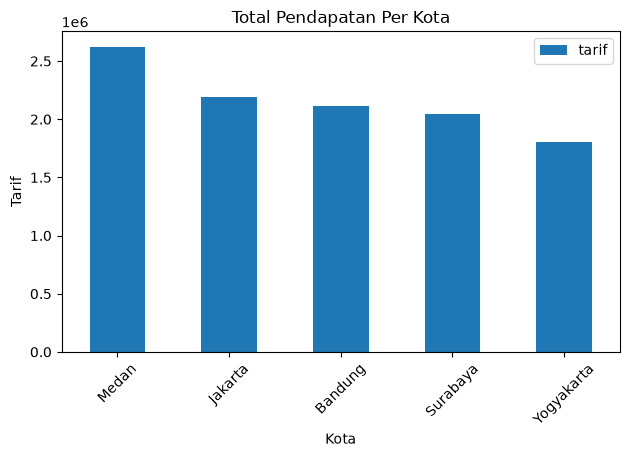

In [30]:
pendapatan_kota.plot(kind='bar', x='kota', y='tarif', title='Total Pendapatan Per Kota')

plt.xlabel('Kota')
plt.ylabel('Tarif')
plt.tight_layout()
plt.xticks(rotation=45)

plt.show()

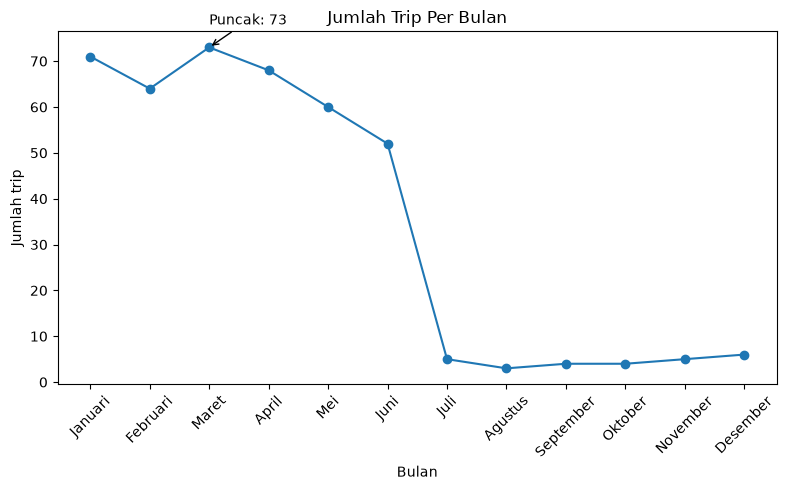

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(trip_bulan['bulan'], trip_bulan['jumlah_trip'], marker='o')

baris_puncak = trip_bulan.loc[trip_bulan['jumlah_trip'].idxmax()]
ax.annotate(
    f"Puncak: {baris_puncak['jumlah_trip']}",
    xy=(baris_puncak['bulan'], baris_puncak['jumlah_trip']),
    xytext=(baris_puncak['bulan'], baris_puncak['jumlah_trip'] + 5),
    arrowprops=dict(arrowstyle='->')
)

ax.set_title('Jumlah Trip Per Bulan')
ax.set_xlabel('Bulan')
ax.set_ylabel('Jumlah trip')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

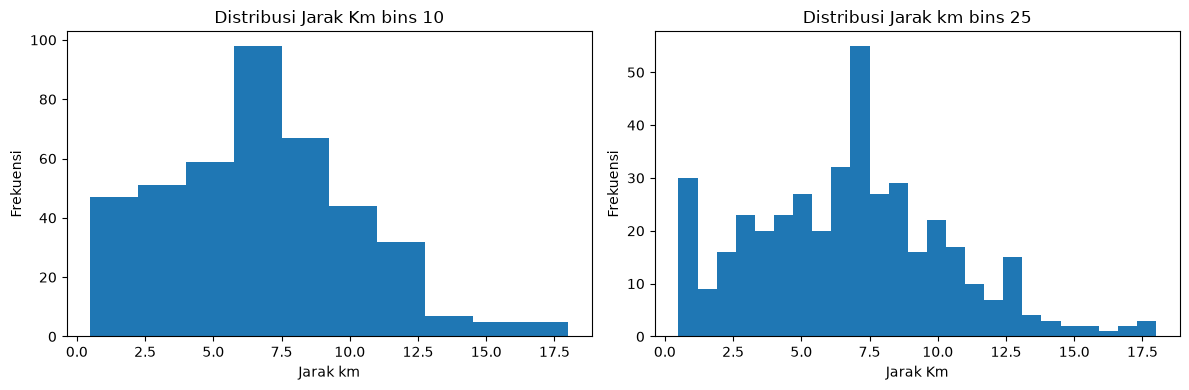

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(dfleft['jarak_km'], bins=10)
axes[0].set_title('Distribusi Jarak Km bins 10')
axes[0].set_xlabel('Jarak km')
axes[0].set_ylabel('Frekuensi')

axes[1].hist(dfleft['jarak_km'], bins=25)
axes[1].set_title('Distribusi Jarak km bins 25')
axes[1].set_xlabel('Jarak Km')
axes[1].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

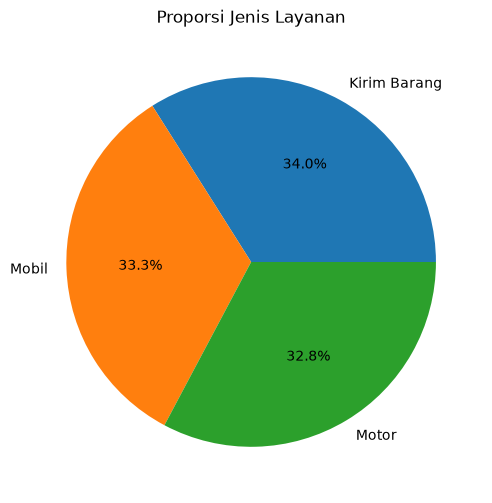

In [33]:
jenis_layanan_counts = dfleft['jenis_layanan'].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    jenis_layanan_counts.values,
    labels=jenis_layanan_counts.index,
    autopct='%1.1f%%'
)
ax.set_title('Proporsi Jenis Layanan')
plt.show()

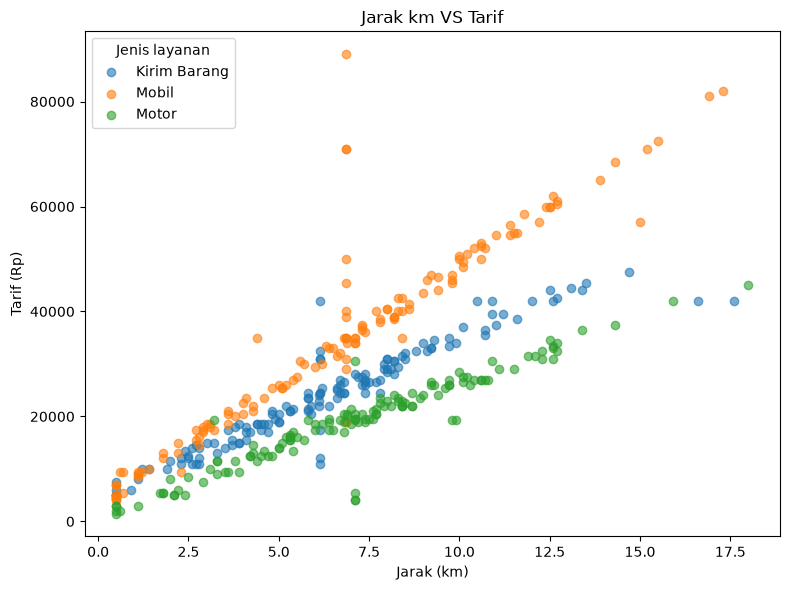

In [34]:
fig, ax = plt.subplots(figsize=(8, 6))

for layanan, grup in dfleft.groupby('jenis_layanan'):
    ax.scatter(grup['jarak_km'], grup['tarif'], label=layanan, alpha=0.6)

ax.set_title('Jarak km VS Tarif')
ax.set_xlabel('Jarak (km)')
ax.set_ylabel('Tarif (Rp)')
ax.ticklabel_format(style='plain', axis='y')
ax.legend(title='Jenis layanan')
plt.tight_layout()
plt.show()

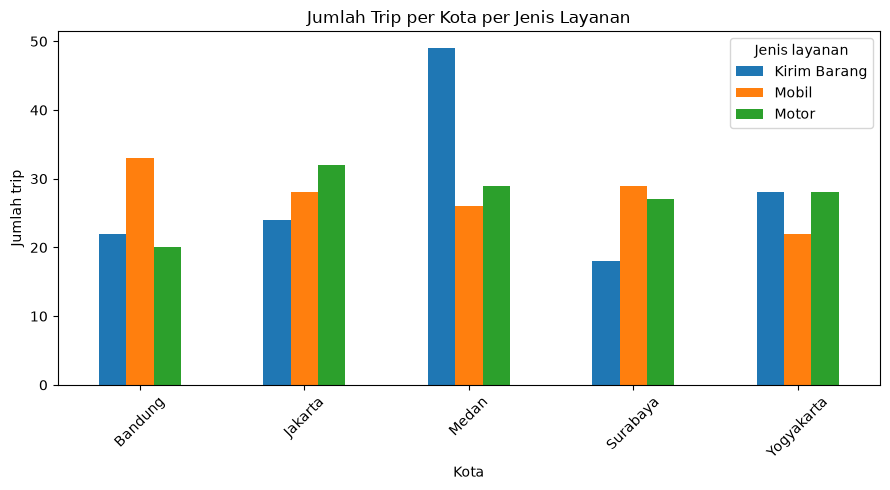

In [35]:
data_plot = pivot_kota.drop(index='Total', columns='Total')

fig, ax = plt.subplots(figsize=(9, 5))
data_plot.plot(kind='bar', ax=ax)

ax.set_title('Jumlah Trip per Kota per Jenis Layanan')
ax.set_xlabel('Kota')
ax.set_ylabel('Jumlah trip')
ax.legend(title='Jenis layanan')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

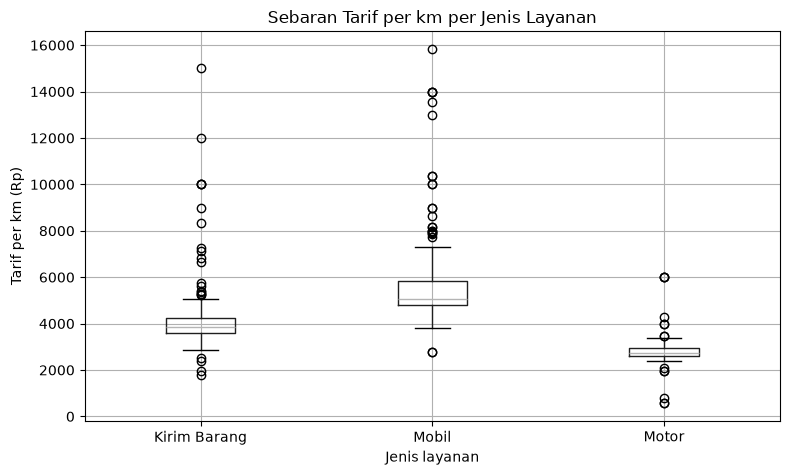

In [36]:
fig, ax = plt.subplots(figsize=(8, 5))
dfleft.boxplot(column='tarif_per_km', by='jenis_layanan', ax=ax)

ax.set_title('Sebaran Tarif per km per Jenis Layanan')
plt.suptitle('')   # hapus judul otomatis "Boxplot grouped by ..."
ax.set_xlabel('Jenis layanan')
ax.set_ylabel('Tarif per km (Rp)')
plt.tight_layout()
plt.show()

In [45]:
trip_per_jam = dfleft.groupby('jam')['trip_id'].count().reindex(range(24), fill_value=0)

urutan_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
trip_per_hari = dfleft.groupby('hari')['trip_id'].count().reindex(urutan_hari)

C:\Users\hpvic\AppData\Local\Temp\ipykernel_18144\4010235941.py:34: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


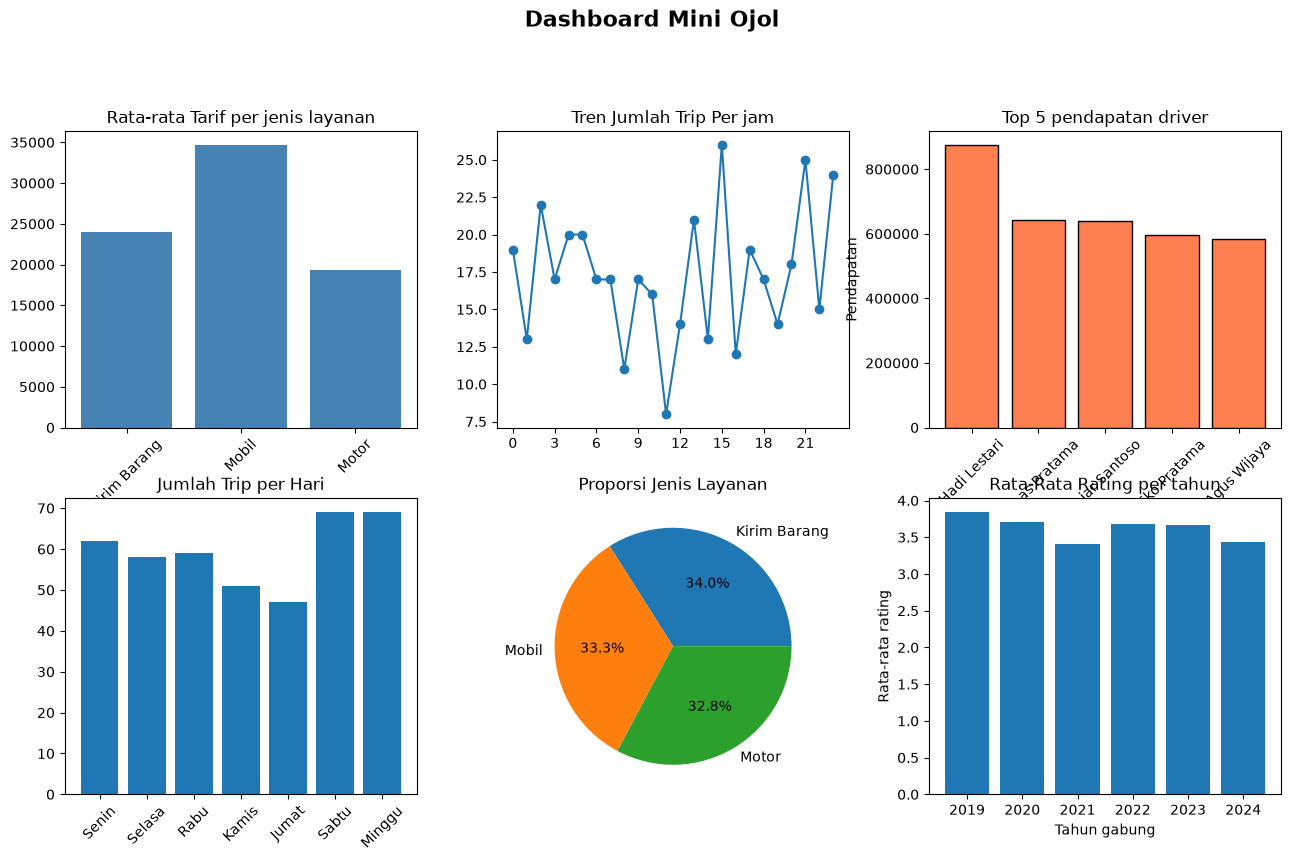

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), constrained_layout=True)

axes[0, 0].bar(ringkasan_per_jenis_layanan['jenis_layanan'], ringkasan_per_jenis_layanan['rata_rata_tarif'], color='steelblue')
axes[0, 0].set_title('Rata-rata Tarif per jenis layanan')
axes[0, 0].tick_params(axis='x', rotation=45)

axes[0, 1].plot(trip_per_jam.index, trip_per_jam.values, marker='o')
axes[0, 1].set_title('Tren Jumlah Trip Per jam')
axes[0, 1].set_xticks(range(0, 24, 3))


axes[1, 0].bar(trip_per_hari.index, trip_per_hari.values)
axes[1, 0].set_title('Jumlah Trip per Hari')
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].xaxis.set_major_locator(plt.MaxNLocator(8))

axes[1, 1].pie(jenis_layanan_counts.values, labels=jenis_layanan_counts.index, autopct='%1.1f%%')
axes[1, 1].set_title('Proporsi Jenis Layanan')

axes[0, 2].bar(top_5_driver_pendapatan['nama_driver'], top_5_driver_pendapatan['total_pendapatan'],
               color='coral', edgecolor='black')
axes[0, 2].set_title('Top 5 pendapatan driver')
axes[0, 2].set_xlabel('Driver')
axes[0, 2].set_ylabel('Pendapatan')
axes[0, 2].tick_params(axis='x', rotation=45)

axes[1, 2].bar(rating_per_tahun2['tahun_gabung'].astype(int).astype(str), rating_per_tahun2['rating'])
axes[1, 2].set_title('Rata-Rata Rating per tahun')
axes[1, 2].set_xlabel('Tahun gabung')
axes[1, 2].set_ylabel('Rata-rata rating')

fig.suptitle('Dashboard Mini Ojol', fontsize=16, fontweight='bold')
fig.savefig('dashboard_ojol.png', dpi=150, bbox_inches='tight')
plt.tight_layout()
plt.show()